## Análise estatística dos dados

Nesse notebook são empregadas as técnicas estatísticas do projeto na base de dados final construída

In [1]:
from utils.load_shp import load_shp

In [2]:
base = load_shp("base.shp")

In [3]:
base.head(3)

,cd_dist,distrito,vt_val_lul,vt_val_fla,vt_validos,vt_branco,vt_nulo,vt_total,pct_val_lu,pct_val_fl,pct_compar,familias_p,pop_total,pbf_mil_ha,n_locais,qt_secoes,qt_eleitor,geometry
0,355030802,Alto de Pinheiros,10376,8583,18959,268,574,19801,54.728625,45.271375,81.873062,717,36987,19.385189,6,65,24185,"POLYGON ((-46.69581 -23.55327, -46.69604 -23.5..."
1,355030803,Anhanguera,23181,14484,37665,591,1118,39374,61.545201,38.454799,82.673330,14600,75967,192.188714,15,128,47626,"POLYGON ((-46.76434 -23.4369, -46.76431 -23.43..."
2,355030804,Aricanduva,24592,28389,52981,844,1987,55812,46.416640,53.583360,80.449730,12412,89499,138.683114,17,207,69375,"POLYGON ((-46.51779 -23.58627, -46.51786 -23.5..."


In [4]:
base['pbf_mil_ha'].describe()

count     96.000000
mean     146.431358
std       74.742421
min       13.072291
25%       95.648813
50%      139.240126
75%      205.852097
max      402.602439
Name: pbf_mil_ha, dtype: float64

In [5]:
base['familias_p'].sum()

np.int64(1819091)

In [6]:
menor = base.nsmallest(1, 'pbf_mil_ha')[['distrito', 'pbf_mil_ha']]

maior = base.nlargest(1, 'pbf_mil_ha')[['distrito', 'pbf_mil_ha']]

display(menor)

display(maior)

,distrito,pbf_mil_ha
51,Moema,13.072291


,distrito,pbf_mil_ha
79,Sé,402.602439


In [7]:
base['pct_val_lu'].describe()

count    96.000000
mean     54.095000
std       6.912289
min      38.812869
25%      48.715086
50%      54.308415
75%      58.940562
max      67.964039
Name: pct_val_lu, dtype: float64

In [8]:
base['vt_val_lul'].sum()

np.int64(3863970)

In [9]:
base['vt_val_fla'].sum()

np.int64(3097838)

In [10]:
menor = base.nsmallest(1, 'pct_val_lu')[['distrito', 'pct_val_lu']]

maior = base.nlargest(1, 'pct_val_lu')[['distrito', 'pct_val_lu']]

display(menor)

display(maior)

,distrito,pct_val_lu
51,Moema,38.812869


,distrito,pct_val_lu
42,Jardim Ângela,67.964039


,N,Média,Desvio-padrão,Mínimo,Mediana,Máximo
Famílias no PBF por mil habitantes,96.0,146.43,74.74,13.07,139.24,402.60
Votos válidos em Lula (%),96.0,54.09,6.91,38.81,54.31,67.96


,Coeficiente,p-valor
Pearson,0.5614,0.0
Spearman,0.5639,0.0


,Queen
Distritos (N),96.00
Média de vizinhos,5.08
Mín. de vizinhos,1.00
Máx. de vizinhos,9.00
Ilhas (sem vizinhos),0.00
Componentes conexos,1.00


,I de Moran,E[I] (permutação),z (permutação),p-valor (pseudo)
Univariado: Famílias no PBF por mil habitantes,0.5204,-0.0096,8.2113,0.0001
Univariado: Votos válidos em Lula (%),0.5996,-0.0101,9.2995,0.0001
Bivariado: Famílias no PBF por mil habitantes × vizinhança de Votos válidos em Lula (%),0.3087,0.0002,4.2220,0.0001


Permutações: 9999 | seed: 42 | pesos: Queen padronizados por linha


,p < 0.05,"p < 0,01",FDR (p < 0.0073)
Alto PBF – vizinhança Alto Lula,12,7,6
Baixo PBF – vizinhança Baixo Lula,16,7,6
Baixo PBF – vizinhança Alto Lula,4,0,0
Alto PBF – vizinhança Baixo Lula,5,2,2
Não significativo,59,80,82
Total,96,96,96


,Distrito,Cluster,Famílias no PBF por mil habitantes,Votos válidos em Lula (%),I local,p-valor
0,Jardim Ângela,Alto PBF – vizinhança Alto Lula,226.080,67.964,1.343,0.002
1,República,Alto PBF – vizinhança Alto Lula,205.772,64.762,0.844,0.002
2,Parelheiros,Alto PBF – vizinhança Alto Lula,231.685,64.783,1.436,0.002
3,Capão Redondo,Alto PBF – vizinhança Alto Lula,192.592,64.208,0.883,0.004
4,José Bonifácio,Alto PBF – vizinhança Alto Lula,163.241,60.508,0.219,0.005
5,Cidade Dutra,Alto PBF – vizinhança Alto Lula,193.622,58.919,0.571,0.005
6,Guaianases,Alto PBF – vizinhança Alto Lula,217.611,62.463,1.202,0.009
7,Grajaú,Alto PBF – vizinhança Alto Lula,229.169,67.152,1.282,0.013
8,Cidade Tiradentes,Alto PBF – vizinhança Alto Lula,259.882,67.561,1.752,0.014
9,Iguatemi,Alto PBF – vizinhança Alto Lula,212.047,63.244,0.702,0.030


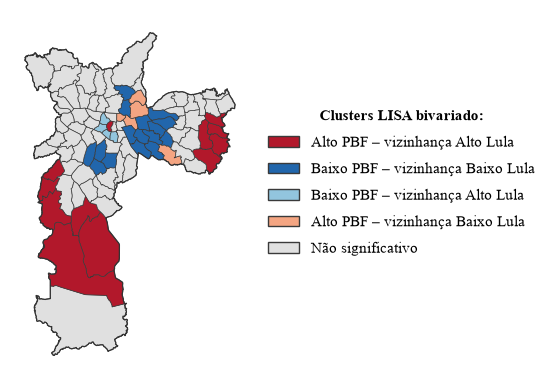

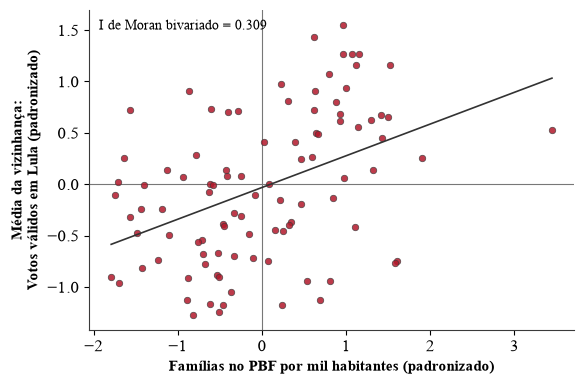

In [11]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path
from scipy import stats
from libpysal.weights import Queen, KNN, lag_spatial
from esda.moran import Moran, Moran_BV, Moran_Local_BV
from esda import fdr

from utils.load_shp import load_shp

# Se save_graph não estiver definido no notebook, usa uma versão simples
try:
    save_graph
except NameError:
    def save_graph(fig, nome):
        Path("resultados").mkdir(exist_ok=True)
        fig.savefig(f"resultados/{nome}.png", dpi=300, bbox_inches="tight", facecolor="white")

# ============================ CONFIGURAÇÃO ============================
X = "pbf_mil_ha"      # x: valor no próprio distrito
Y = "pct_val_lu"      # y: média dos vizinhos (lag espacial)
NOME_X = "Famílias no PBF por mil habitantes"
NOME_Y = "Votos válidos em Lula (%)"
PERM = 9999
SEED = 42
ALPHA = 0.05
OUT = Path("resultados"); OUT.mkdir(exist_ok=True)

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman', 'Liberation Serif', 'DejaVu Serif']
plt.rcParams['font.size'] = 12
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'

def salvar(df, nome):
    """Salva CSV pronto para Excel pt-BR e devolve o df."""
    df.to_csv(OUT / f"{nome}.csv", sep=";", decimal=",", encoding="utf-8-sig")
    return df

def centralizar_em_caixa(ax, mapa, margem=0.07):
    minx, miny, maxx, maxy = mapa.total_bounds
    dx, dy = maxx - minx, maxy - miny
    ax.set_xlim(minx - dx * margem, maxx + dx * margem)
    ax.set_ylim(miny - dy * margem, maxy + dy * margem)

np.random.seed(SEED)
base = load_shp("base.shp")
base = base.to_crs(epsg=31983)
base[X] = base[X].astype(float)
base[Y] = base[Y].astype(float)

# ============================ TABELA 1: DESCRITIVAS ============================
desc = base[[X, Y]].agg(["count", "mean", "std", "min", "median", "max"]).T
desc.index = [NOME_X, NOME_Y]
desc.columns = ["N", "Média", "Desvio-padrão", "Mínimo", "Mediana", "Máximo"]
display(salvar(desc.round(2), "tab1_descritivas"))

# ============================ TABELA 2: CORRELAÇÃO NÃO ESPACIAL ============================
pr, pp = stats.pearsonr(base[X], base[Y])
sr, sp = stats.spearmanr(base[X], base[Y])
corr = pd.DataFrame({"Coeficiente": [pr, sr], "p-valor": [pp, sp]},
                    index=["Pearson", "Spearman"])
display(salvar(corr.round(4), "tab2_correlacao"))

# ============================ PESOS ESPACIAIS ============================
w = Queen.from_dataframe(base, use_index=False)
w.transform = "r"   # padronização por linha

if len(w.islands) > 0:
    print("ATENÇÃO: há ilhas na matriz Queen; usando KNN (k=6).")
    w = KNN.from_dataframe(base, k=6)
    w.transform = "r"

diag = pd.Series({
    "Distritos (N)": w.n,
    "Média de vizinhos": round(w.mean_neighbors, 2),
    "Mín. de vizinhos": w.min_neighbors,
    "Máx. de vizinhos": w.max_neighbors,
    "Ilhas (sem vizinhos)": len(w.islands),
    "Componentes conexos": w.n_components,
}, name=type(w).__name__)
display(salvar(diag.to_frame(), "tab3_diagnostico_pesos"))

# ============================ TABELA 4: MORAN GLOBAL ============================
mx = Moran(base[X], w, permutations=PERM)
my = Moran(base[Y], w, permutations=PERM)
mbv = Moran_BV(base[X], base[Y], w, permutations=PERM)

tab_moran = pd.DataFrame({
    "I de Moran": [mx.I, my.I, mbv.I],
    "E[I] (permutação)": [mx.EI_sim, my.EI_sim, mbv.EI_sim],
    "z (permutação)": [mx.z_sim, my.z_sim, mbv.z_sim],
    "p-valor (pseudo)": [mx.p_sim, my.p_sim, mbv.p_sim],
}, index=[
    f"Univariado: {NOME_X}",
    f"Univariado: {NOME_Y}",
    f"Bivariado: {NOME_X} × vizinhança de {NOME_Y}",
])
display(salvar(tab_moran.round(4), "tab4_moran_global"))
print(f"Permutações: {PERM} | seed: {SEED} | pesos: {type(w).__name__} padronizados por linha")

# ============================ LISA BIVARIADO ============================
lisa = Moran_Local_BV(base[X], base[Y], w, permutations=PERM, seed=SEED)

# quadrantes do esda: 1=HH, 2=LH, 3=LL, 4=HL (x no distrito / y na vizinhança)
rotulos = {
    1: "Alto PBF – vizinhança Alto Lula",
    2: "Baixo PBF – vizinhança Alto Lula",
    3: "Baixo PBF – vizinhança Baixo Lula",
    4: "Alto PBF – vizinhança Baixo Lula",
}
corpal = {
    "Alto PBF – vizinhança Alto Lula": "#b2182b",
    "Baixo PBF – vizinhança Baixo Lula": "#2166ac",
    "Baixo PBF – vizinhança Alto Lula": "#92c5de",
    "Alto PBF – vizinhança Baixo Lula": "#f4a582",
    "Não significativo": "#e0e0e0",
}

base["lisa_I"] = lisa.Is
base["lisa_p"] = lisa.p_sim
base["lisa_q"] = lisa.q

p_fdr = fdr(base["lisa_p"].values, alpha=ALPHA)   # limiar Benjamini-Hochberg

def classifica(p, q, limiar):
    return rotulos[q] if p < limiar else "Não significativo"

base["cluster"] = [classifica(p, q, ALPHA) for p, q in zip(base["lisa_p"], base["lisa_q"])]
base["cluster_p01"] = [classifica(p, q, 0.01) for p, q in zip(base["lisa_p"], base["lisa_q"])]
base["cluster_fdr"] = [classifica(p, q, p_fdr) for p, q in zip(base["lisa_p"], base["lisa_q"])]

# ============================ TABELA 5: CONTAGEM DE CLUSTERS ============================
ordem = list(corpal.keys())
contagem = pd.DataFrame({
    f"p < {ALPHA}": base["cluster"].value_counts(),
    "p < 0,01": base["cluster_p01"].value_counts(),
    f"FDR (p < {p_fdr:.4f})": base["cluster_fdr"].value_counts(),
}).reindex(ordem).fillna(0).astype(int)
contagem.loc["Total"] = contagem.sum()
display(salvar(contagem, "tab5_contagem_clusters"))

# ============================ TABELA 6: DISTRITOS POR CLUSTER ============================
tab_dist = (
    base[base["cluster"] != "Não significativo"]
    .sort_values(["cluster", "lisa_p"])
    [["distrito", "cluster", X, Y, "lisa_I", "lisa_p"]]
    .rename(columns={"distrito": "Distrito", "cluster": "Cluster",
                     X: NOME_X, Y: NOME_Y,
                     "lisa_I": "I local", "lisa_p": "p-valor"})
    .round(3).reset_index(drop=True)
)
display(salvar(tab_dist, "tab6_distritos_por_cluster"))

# Anexo: resultado completo por distrito
salvar(base[["distrito", X, Y, "lisa_I", "lisa_p", "cluster"]].round(4)
       .set_index("distrito"), "anexo_lisa_todos_distritos")

# ============================ MAPA DE CLUSTERS ============================
base["cor"] = base["cluster"].map(corpal)

fig, ax = plt.subplots(figsize=(8, 4))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

base.plot(color=base["cor"], linewidth=0.5, edgecolor='#3a3a3a', ax=ax, zorder=2)
base.dissolve().boundary.plot(ax=ax, color='#333333', linewidth=0.9, zorder=3)

ax.set_aspect('equal')
centralizar_em_caixa(ax, base, margem=0.07)

handles = [Patch(facecolor=c, edgecolor='#3a3a3a') for c in corpal.values()]
ax.legend(
    handles, list(corpal.keys()),
    title='Clusters LISA bivariado:',
    loc='center left',
    bbox_to_anchor=(1.02, 0.53),
    frameon=False,
    fontsize=11,
    title_fontproperties={'size': 11, 'weight': 'bold'},
    labelspacing=0.8,
)
ax.set_axis_off()
plt.subplots_adjust(left=0.02, right=0.58, top=0.96, bottom=0.04)

save_graph(fig, 'mapa_lisa_bv_pbf_lula')
plt.show()

# ============================ DIAGRAMA DE DISPERSÃO DE MORAN BIVARIADO ============================
zx = (base[X] - base[X].mean()) / base[X].std(ddof=0)
zy = (base[Y] - base[Y].mean()) / base[Y].std(ddof=0)
wzy = lag_spatial(w, zy)

fig, ax = plt.subplots(figsize=(6, 4))
fig.patch.set_facecolor('white')

ax.scatter(zx, wzy, s=22, color='#b2182b', edgecolor='#3a3a3a',
           linewidth=0.5, alpha=0.85, zorder=3)
b, a = np.polyfit(zx, wzy, 1)
xs = np.linspace(zx.min(), zx.max(), 100)
ax.plot(xs, a + b * xs, color='#333333', linewidth=1.2, zorder=4)
ax.axhline(0, color='#777777', linewidth=0.8, zorder=1)
ax.axvline(0, color='#777777', linewidth=0.8, zorder=1)

ax.set_xlabel(f'{NOME_X} (padronizado)', fontsize=11, fontweight='bold')
ax.set_ylabel('Média da vizinhança:\nVotos válidos em Lula (padronizado)',
              fontsize=11, fontweight='bold')
ax.text(0.02, 0.97, f'I de Moran bivariado = {mbv.I:.3f}', transform=ax.transAxes,
        ha='left', va='top', fontsize=10)
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
for s in ['left', 'bottom']:
    ax.spines[s].set_color('#3a3a3a')

plt.tight_layout()
save_graph(fig, 'dispersao_moran_bv')
plt.show()